# Laboratory 04 — Multiple Linear Regression Analysis
**Course:** Introduction to Artificial Intelligence (AI-101L)  
**Instructor:** Dr. Muhammad Awais  
**Topic:** Multivariate Supervised Learning — Predicting Real Estate Prices from Multiple Architectural & Spatial Attributes

---

## 1. Mathematical Formulation
Multiple Linear Regression models the expected target variable $y$ as a linear combination of $p$ explanatory features:

$$\hat{y} = \beta_0 + \sum_{j=1}^p \beta_j X_j = X \beta$$

In matrix notation:
$$\mathbf{y} = \mathbf{X}\boldsymbol{\beta} + \boldsymbol{\epsilon}$$

The Ordinary Least Squares (OLS) closed-form solution minimizing the Sum of Squared Residuals (SSR) is:
$$\boldsymbol{\hat{\beta}} = (\mathbf{X}^T \mathbf{X})^{-1} \mathbf{X}^T \mathbf{y}$$

The Adjusted $R^2$ penalizes irrelevant predictor features:
$$R^2_{\text{adj}} = 1 - \left[\frac{(1 - R^2)(n - 1)}{n - p - 1}\right]$$


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("Libraries loaded successfully.")


Libraries loaded successfully.


## 2. Dataset Ingestion and Exploratory Analysis

In [2]:
# Load the house price regression dataset
data_path = "house_price_regression_dataset.csv"
if not os.path.exists(data_path):
    data_path = os.path.join(os.path.dirname(__file__) if '__file__' in locals() else '.', "house_price_regression_dataset.csv")

df = pd.read_csv(data_path)
print(f"Dataset Dimensions: {df.shape[0]} houses, {df.shape[1]} attributes")
print("\nSummary Statistics:")
display(df.describe().T.round(2))


Dataset Dimensions: 1000 houses, 8 attributes

Summary Statistics:
                       count       mean  ...        75%         max
Square_Footage        1000.0    2815.42  ...    3849.50     4999.00
Num_Bedrooms          1000.0       2.99  ...       4.00        5.00
Num_Bathrooms         1000.0       1.97  ...       3.00        3.00
Year_Built            1000.0    1986.55  ...    2004.25     2022.00
Lot_Size              1000.0       2.78  ...       3.92        4.99
Garage_Size           1000.0       1.02  ...       2.00        2.00
Neighborhood_Quality  1000.0       5.62  ...       8.00       10.00
House_Price           1000.0  618861.02  ...  827141.28  1108236.84

[8 rows x 8 columns]


<ipython-input-1-5605ef55ce90>:6: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


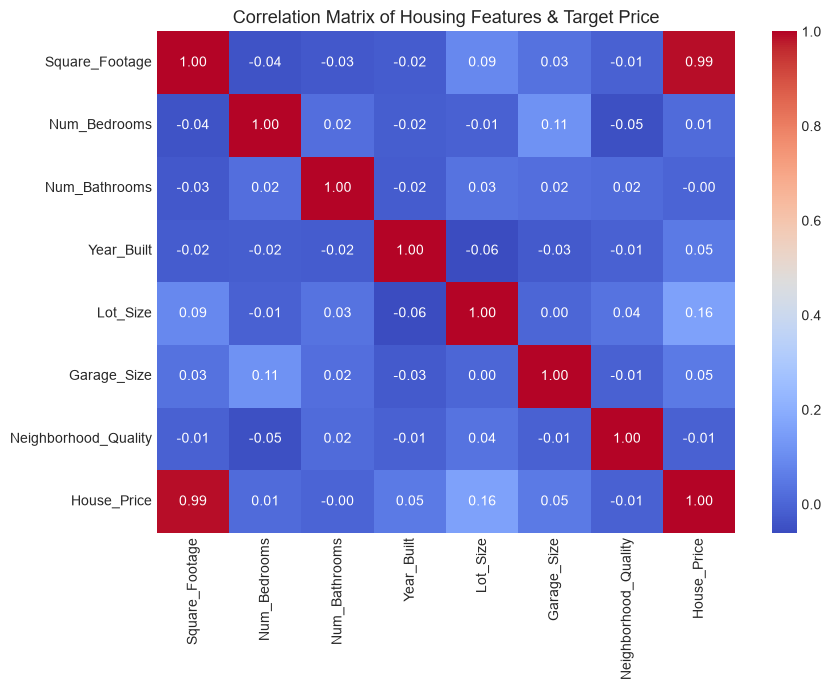

In [3]:
# Correlation heatmap
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', cbar=True)
plt.title("Correlation Matrix of Housing Features & Target Price", fontsize=13)
plt.tight_layout()
plt.show()


## 3. Feature Selection & Train-Test Partitioning

In [4]:
feature_cols = [
    'Square_Footage', 'Num_Bedrooms', 'Num_Bathrooms', 
    'Year_Built', 'Lot_Size', 'Garage_Size', 'Neighborhood_Quality'
]
target_col = 'House_Price'

X = df[feature_cols]
y = df[target_col]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Train split: {X_train.shape[0]} records | Test split: {X_test.shape[0]} records")


Train split: 800 records | Test split: 200 records


## 4. Model Training & Coefficient Interpretation

In [5]:
model = LinearRegression()
model.fit(X_train, y_train)

# Format and display learned coefficients
coef_df = pd.DataFrame({
    'Feature': feature_cols,
    'Coefficient (Beta)': model.coef_,
    'Abs Impact': np.abs(model.coef_)
}).sort_values(by='Abs Impact', ascending=False).reset_index(drop=True)

print(f"Model Intercept (Beta_0): ${model.intercept_:,.2f}\n")
print("Learned Feature Weights:")
print(coef_df[['Feature', 'Coefficient (Beta)']].to_string(index=False))


Model Intercept (Beta_0): $-2,010,567.42

Learned Feature Weights:
             Feature  Coefficient (Beta)
            Lot_Size        14885.384415
        Num_Bedrooms        10225.204426
       Num_Bathrooms         8208.434772
         Garage_Size         5146.148387
          Year_Built          993.537171
      Square_Footage          199.513245
Neighborhood_Quality          115.068595


## 5. Test Set Predictions and Performance Evaluation
*(Fixing the indexing bug from the legacy code to correctly evaluate test instances)*


In [6]:
y_predict = model.predict(X_test)

# Prediction audit table
audit_df = pd.DataFrame({
    'Square_Footage': X_test['Square_Footage'].values,
    'Bedrooms': X_test['Num_Bedrooms'].values,
    'Bathrooms': X_test['Num_Bathrooms'].values,
    'Quality': X_test['Neighborhood_Quality'].values,
    'Actual Price': y_test.values,
    'Predicted Price': np.round(y_predict, 2),
    'Absolute Error': np.round(np.abs(y_test.values - y_predict), 2),
    'Error %': np.round(np.abs(y_test.values - y_predict) / y_test.values * 100, 2)
})

print("First 10 Test Sample Predictions:")
print(audit_df.head(10).to_string(index=False))


First 10 Test Sample Predictions:
 Square_Footage  Bedrooms  Bathrooms  Quality  Actual Price  Predicted Price  Absolute Error  Error %
           4012         3          1        5   901000.4882        868687.11        32313.38     3.59
           2310         3          1        4   494537.5115        490337.90         4199.61     0.85
           4708         1          3        8   949404.2007        945667.12         3737.08     0.39
           4932         2          1        2  1040389.0480       1033402.88         6986.17     0.67
           3646         1          1        9   794010.0167        776698.77        17311.24     2.18
           3586         2          2       10   724033.5605        732444.09         8410.53     1.16
           4638         4          3        3   998439.2371        995051.99         3387.25     0.34
           4127         5          2        1   909713.4350        885174.77        24538.67     2.70
           3781         2          1        9   

In [7]:
# Performance metrics
n = len(y_test)
p = X_test.shape[1]

mae = mean_absolute_error(y_test, y_predict)
mse = mean_squared_error(y_test, y_predict)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_predict)
adj_r2 = 1 - ((1 - r2) * (n - 1) / (n - p - 1))

print("=== Multivariate Linear Regression Evaluation Metrics ===")
print(f"Mean Absolute Error (MAE)            : ${mae:,.2f}")
print(f"Mean Squared Error (MSE)             : ${mse:,.2f}")
print(f"Root Mean Squared Error (RMSE)       : ${rmse:,.2f}")
print(f"R-squared (R2 Score)                 : {r2:.5f}")
print(f"Adjusted R-squared (Adj R2)          : {adj_r2:.5f}")


=== Multivariate Linear Regression Evaluation Metrics ===
Mean Absolute Error (MAE)            : $8,174.58
Mean Squared Error (MSE)             : $101,434,798.45
Root Mean Squared Error (RMSE)       : $10,071.48
R-squared (R2 Score)                 : 0.99843
Adjusted R-squared (Adj R2)          : 0.99837


## 6. Diagnostic Evaluation Plots

<ipython-input-1-88fbaeca8f7e>:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


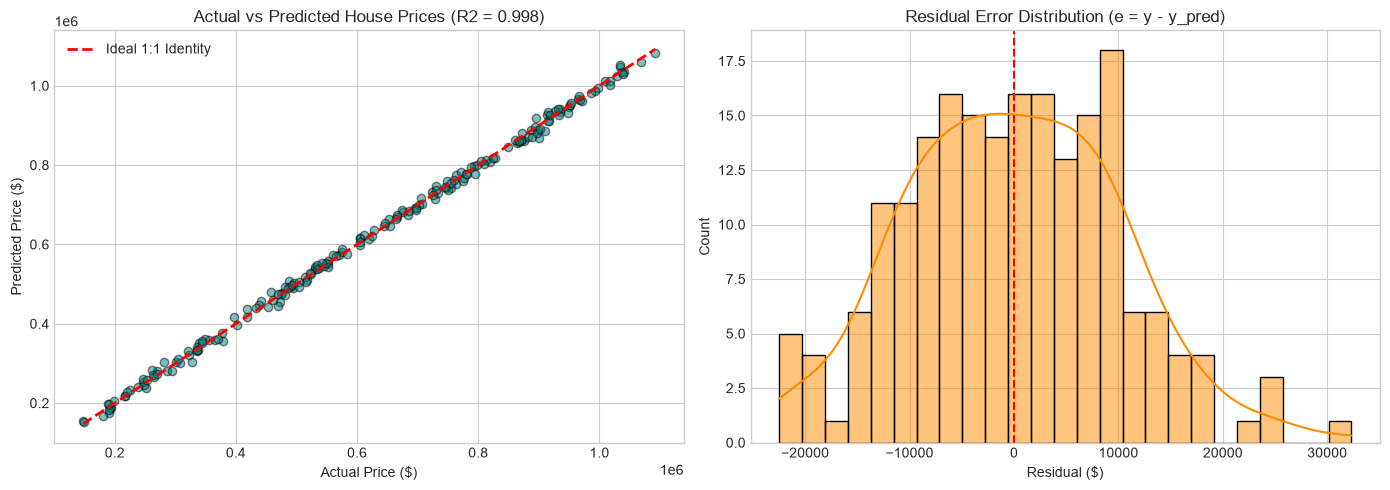

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Actual vs Predicted Scatter with 45-degree identity line
axes[0].scatter(y_test, y_predict, alpha=0.5, color='teal', edgecolor='k')
min_val = min(y_test.min(), y_predict.min())
max_val = max(y_test.max(), y_predict.max())
axes[0].plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Ideal 1:1 Identity')
axes[0].set_title(f"Actual vs Predicted House Prices (R2 = {r2:.3f})", fontsize=12)
axes[0].set_xlabel("Actual Price ($)")
axes[0].set_ylabel("Predicted Price ($)")
axes[0].legend()

# Plot 2: Residual Distribution
residuals = y_test - y_predict
sns.histplot(residuals, kde=True, ax=axes[1], color='darkorange', bins=25)
axes[1].axvline(0, color='red', linestyle='--')
axes[1].set_title("Residual Error Distribution (e = y - y_pred)", fontsize=12)
axes[1].set_xlabel("Residual ($)")

plt.tight_layout()
plt.show()
